In [8]:
import os
import cv2
import numpy as np
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import glob
import tensorflow as tf
from sklearn.utils.class_weight import compute_class_weight

ROOT = r"C:\Users\Chair\Desktop\simpsons\simpsons_dataset"
TEST_DIR = r"C:\Users\Chair\Desktop\simpsons\kaggle_simpson_testset"
IMG_SIZE = 64
MAX_PER_CLASS = 1000

TEST_DIR = r"C:\Users\Chair\Desktop\simpsons\kaggle_simpson_testset\kaggle_simpson_testset"

map_characters = {0: 'abraham_grampa_simpson', 1: 'apu_nahasapeemapetilon', 2: 'bart_simpson',
        3: 'charles_montgomery_burns', 4: 'chief_wiggum', 5: 'comic_book_guy', 6: 'edna_krabappel',
        7: 'homer_simpson', 8: 'kent_brockman', 9: 'krusty_the_clown', 10: 'lisa_simpson',
        11: 'marge_simpson', 12: 'milhouse_van_houten', 13: 'moe_szyslak',
        14: 'ned_flanders', 15: 'nelson_muntz', 16: 'principal_skinner', 17: 'sideshow_bob'}
num_classes = len(map_characters)
class_labels = [map_characters[index].replace("_", " ").title() for index in range(num_classes)]



print(os.listdir(ROOT)[:5])

#step 1 init

['abraham_grampa_simpson', 'agnes_skinner', 'apu_nahasapeemapetilon', 'barney_gumble', 'bart_simpson']


In [3]:
%pip install tensorflow opencv-python scikit-learn numpy matplotlib

   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 2.1/351.2 MB 15.8 MB/s eta 0:00:23
   - -------------------------------------- 14.7/351.2 MB 45.5 MB/s eta 0:00:08
   --- ------------------------------------ 32.2/351.2 MB 60.8 MB/s eta 0:00:06
   ----- ---------------------------------- 51.6/351.2 MB 70.4 MB/s eta 0:00:05
   -------- ------------------------------- 71.0/351.2 MB 76.1 MB/s eta 0:00:04
   ---------- ----------------------------- 90.4/351.2 MB 79.4 MB/s eta 0:00:04
   ------------ -------------------------- 111.7/351.2 MB 82.4 MB/s eta 0:00:03
   -------------- ------------------------ 131.9/351.2 MB 84.8 MB/s eta 0:00:03
   ---------------- ---------------------- 152.3/351.2 MB 86.7 MB/s eta 0:00:03
   ------------------- ------------------- 173.3/351.2 MB 88.4 MB/s eta 0:00:03
   --------------------- ----------------- 194.0/351.2 MB 89.7 MB/s eta 0:00:02
   ----------------------- --------------- 215.0/3

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
streamlit 1.45.1 requires protobuf<7,>=3.20, but you have protobuf 7.36.2 which is incompatible.


In [2]:
def load_training_data(root, characters, image_size, max_per_class):
    images = []
    labels = []
    for label, name in characters.items():
        paths = sorted(glob.glob(os.path.join(root, name, "*")))
        np.random.seed(42)
        np.random.shuffle(paths)
        for path in paths[:max_per_class]:
            try:
                image = tf.keras.utils.load_img(path, target_size=(image_size, image_size))
                images.append(tf.keras.utils.img_to_array(image, dtype="uint8"))
                labels.append(label)
            except Exception:
                continue
    return np.array(images, dtype="uint8"), np.array(labels, dtype="int32")


def load_test_data(test_dir, characters, image_size):
    name_to_label = {name: label for label, name in characters.items()}
    images = []
    labels = []
    for path in sorted(glob.glob(os.path.join(test_dir, "*.jpg"))):
        file_name = os.path.basename(path)
        character_name = "_".join(file_name.split("_")[:-1])
        if character_name not in name_to_label:
            continue
        try:
            image = tf.keras.utils.load_img(path, target_size=(image_size, image_size))
            images.append(tf.keras.utils.img_to_array(image, dtype="uint8"))
            labels.append(name_to_label[character_name])
        except Exception:
            continue
    return np.array(images, dtype="uint8"), np.array(labels, dtype="int32")


images, labels = load_training_data(ROOT, map_characters, IMG_SIZE, MAX_PER_CLASS)
test_images, test_labels = load_test_data(TEST_DIR, map_characters, IMG_SIZE)
print(images.shape, test_images.shape)   # expect 15181 training images, 890 test images

train_images, val_images, train_labels, val_labels = train_test_split(
    images, labels, test_size=0.2, stratify=labels, random_state=42
)

weights = compute_class_weight("balanced", classes=np.unique(train_labels), y=train_labels)
class_weights = dict(enumerate(weights))

(15181, 64, 64, 3) (0,)


In [3]:
def build_pretrained_model(image_size, num_classes):
    base_model = keras.applications.MobileNetV2(
        input_shape=(image_size, image_size, 3),
        include_top=False,
        weights="imagenet",
    )
    base_model.trainable = False

    inputs = keras.Input(shape=(image_size, image_size, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.15)(x)
    x = layers.RandomContrast(0.1)(x)
    x = layers.Rescaling(1.0 / 127.5, offset=-1)(x)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs)


model = build_pretrained_model(IMG_SIZE, num_classes)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history = model.fit(
    train_images, train_labels,
    validation_data=(val_images, val_labels),
    epochs=15,
    batch_size=64,
    class_weight=class_weights,
)

C:\Users\Chair\AppData\Local\Temp\ipykernel_26120\532003658.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = keras.applications.MobileNetV2(


Epoch 1/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.1775 - loss: 2.8696 - val_accuracy: 0.2812 - val_loss: 2.3416
Epoch 2/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.2820 - loss: 2.3890 - val_accuracy: 0.3336 - val_loss: 2.1870
Epoch 3/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.3181 - loss: 2.2412 - val_accuracy: 0.3546 - val_loss: 2.1336
Epoch 4/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.3362 - loss: 2.1797 - val_accuracy: 0.3694 - val_loss: 2.1056
Epoch 5/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.3556 - loss: 2.1350 - val_accuracy: 0.3872 - val_loss: 2.0539
Epoch 6/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 33ms/step - accuracy: 0.3598 - loss: 2.1013 - val_accuracy: 0.3978 - val_loss: 2.0474
Epoch 7/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 8s 40ms/step - accuracy: 0.3621 - loss: 2.0870 - val_accuracy: 0.4007 - val_loss: 2.0092
Epoch 8/15
190/190 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.3682 - loss: 2.0745 - val_acc

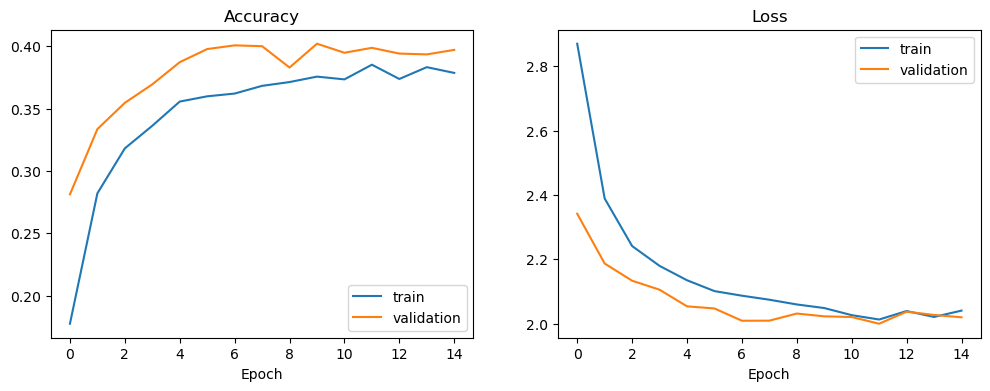

In [4]:
#plot it
import matplotlib.pyplot as plt

def plot_history(history):
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(history.history["accuracy"], label="train")
    axes[0].plot(history.history["val_accuracy"], label="validation")
    axes[0].set_title("Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history.history["loss"], label="train")
    axes[1].plot(history.history["val_loss"], label="validation")
    axes[1].set_title("Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.show()

plot_history(history)

#plot

In [12]:
def plot_confusion_matrix(true_labels, predicted_labels, class_names):
    matrix = confusion_matrix(true_labels, predicted_labels)
    plt.figure(figsize=(14, 12))
    plt.imshow(matrix, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=90, fontsize=8)
    plt.yticks(range(len(class_names)), class_names, fontsize=8)

    threshold = matrix.max() / 2
    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[row_index, column_index]
            if value == 0:
                continue
            text_color = "white" if value > threshold else "black"
            plt.text(column_index, row_index, str(value),
                     ha="center", va="center", color=text_color, fontsize=7)

    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.tight_layout()
    plt.show()

                          precision    recall  f1-score   support

  Abraham Grampa Simpson      0.300     0.500     0.375        48
  Apu Nahasapeemapetilon      0.775     0.620     0.689        50
            Bart Simpson      0.571     0.240     0.338        50
Charles Montgomery Burns      0.300     0.500     0.375        48
            Chief Wiggum      0.547     0.580     0.563        50
          Comic Book Guy      0.316     0.510     0.391        49
          Edna Krabappel      0.429     0.300     0.353        50
           Homer Simpson      0.190     0.080     0.113        50
           Kent Brockman      0.727     0.640     0.681        50
        Krusty The Clown      0.464     0.520     0.491        50
            Lisa Simpson      0.500     0.200     0.286        50
           Marge Simpson      0.290     0.360     0.321        50
     Milhouse Van Houten      0.552     0.327     0.410        49
             Moe Szyslak      0.688     0.440     0.537        50
         

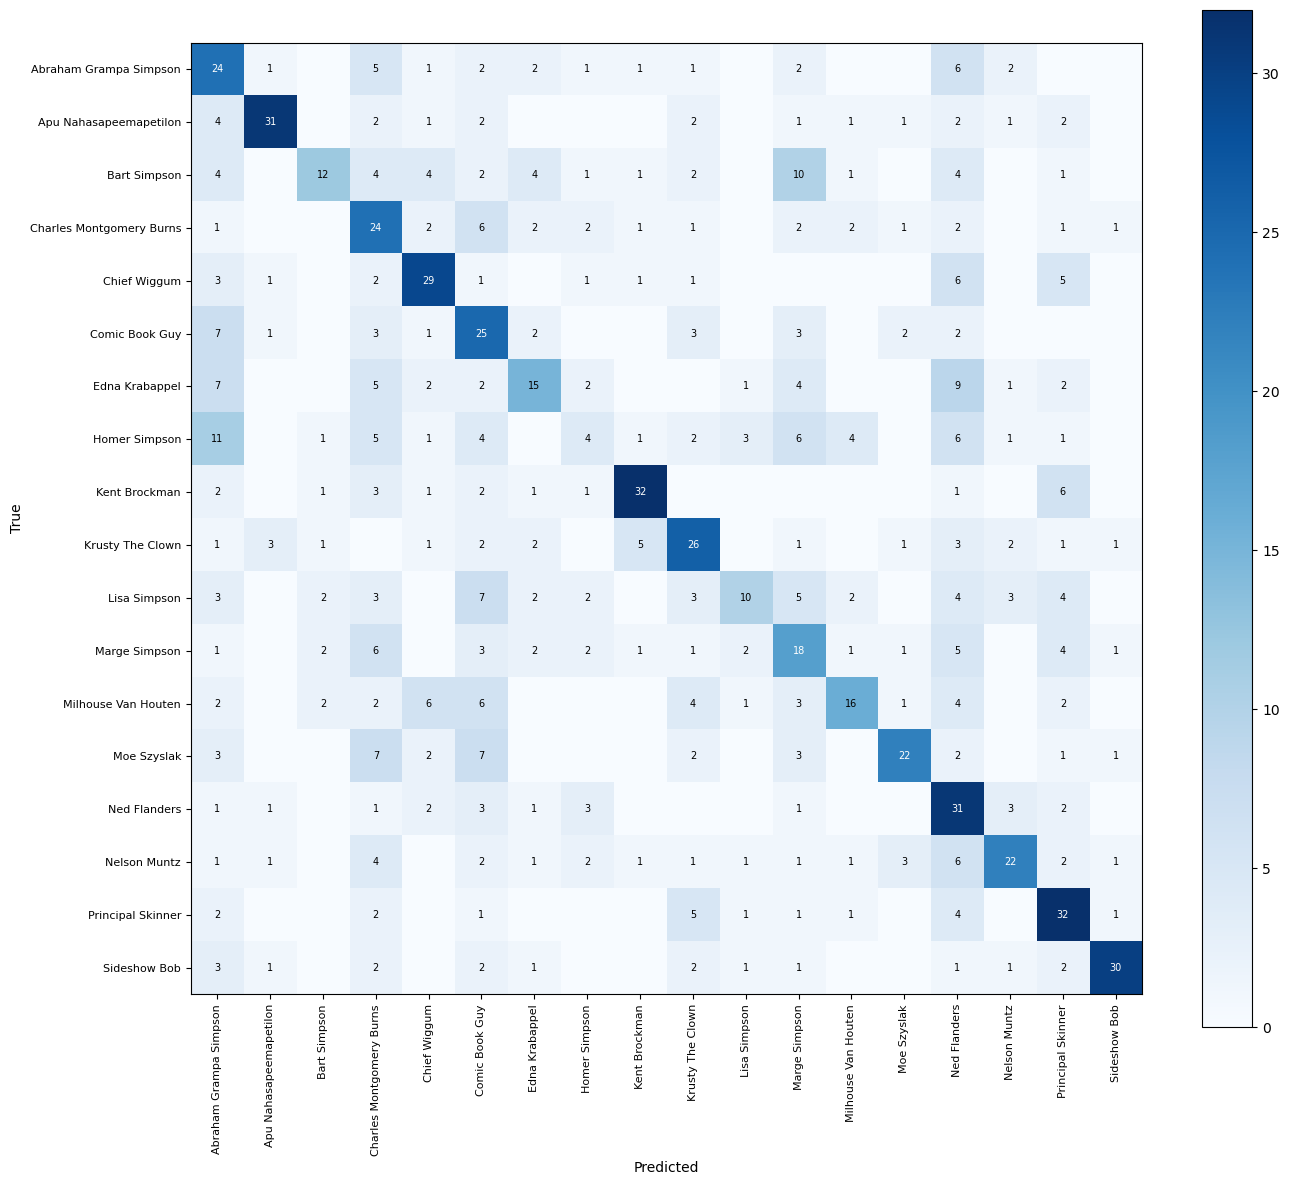

In [13]:
test_predictions = np.argmax(model.predict(test_images, batch_size=64, verbose=0), axis=1)
print(classification_report(test_labels, test_predictions, target_names=class_labels, digits=3))
plot_confusion_matrix(test_labels, test_predictions, class_labels)

In [10]:
print(os.path.isdir(TEST_DIR))
print(os.listdir(TEST_DIR)[:5])

test_images, test_labels = load_test_data(TEST_DIR, map_characters, IMG_SIZE)
print(test_images.shape)

True
['abraham_grampa_simpson_0.jpg', 'abraham_grampa_simpson_1.jpg', 'abraham_grampa_simpson_10.jpg', 'abraham_grampa_simpson_11.jpg', 'abraham_grampa_simpson_12.jpg']
(890, 64, 64, 3)
